# Module 4: E-Commerce Customer Churn Prediction & Retention Strategy
### Senior Data Scientist & ML Engineering Portfolio
---
### Objectives:
1. **Defensible Business Churn Formulation**: Overcome the non-contractual ambiguity by instituting a 90-day future inactivity window cutoff.
2. **Leak-Free Feature Store**: Calculate historical customer features (Recency, Frequency, Monetary, Unique SKUs, Inter-Purchase Velocity) strictly before the cutoff date.
3. **Classification Benchmarking**: Train and evaluate **Logistic Regression**, **Random Forest**, and **XGBoost Classifiers** using Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
4. **Prioritizing Recall in Retention**: Explain why false negatives (missing a churning VIP) are far more costly to retail EBITDA than false positives.
5. **VIP Revenue Exposure**: Identify high-value accounts at immediate risk of churning and prescribe high-touch retention workflows.


In [1]:
import sys
from pathlib import Path
sys.path.append('..')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (10, 5)


## 1. Out-of-Time Churn Feature Engineering
We use `src.features.churn_features.ChurnFeatureEngineer` to segment the historical timeline.
- Cutoff Date: `2011-09-10`
- Target: 1 if 0 purchases made between `2011-09-10` and `2011-12-09` (90-day window); 0 otherwise.


In [2]:
from src.features.churn_features import ChurnFeatureEngineer

fe = ChurnFeatureEngineer(data_path=Path('../data/processed/online_retail_customer_centric.csv'), churn_window_days=90)
churn_df = fe.engineer_churn_features()
churn_df.head()


[Churn] Total Horizon: 2010-12-01 to 2011-12-09
[Churn] Observation Cutoff Date: 2011-09-10
[Churn] Future Evaluation Window: 2011-09-10 to 2011-12-09 (90 days)
[Churn] Customers active prior to cutoff: 3,368
[Churn] Feature dataset saved to /Users/aryangupta/Desktop/e-commerce/data/processed/customer_churn_features.csv (3368 customers).
[Churn] Ground-Truth Churn Rate: 43.02% (1449 churned, 1919 retained).


,CustomerID,Recency,HistoricalFrequency,HistoricalMonetary,HistoricalUnits,UniqueSKUs,Tenure,AOV,UnitsPerOrder,PurchaseVelocity,Churn
0,12346,235,1,77183.60,74215,1,235,77183.6000,74215.000000,235.000000,1
1,12347,39,5,2790.86,1590,82,276,558.1720,318.000000,69.000000,0
2,12348,158,3,1167.24,2116,21,267,389.0800,705.333333,133.500000,0
3,12350,219,1,294.40,196,16,219,294.4000,196.000000,219.000000,1
4,12352,171,4,641.51,249,24,206,160.3775,62.250000,68.666667,0


## 2. Ground-Truth Churn Distribution
Examining the natural balance between retained and churned cohorts.


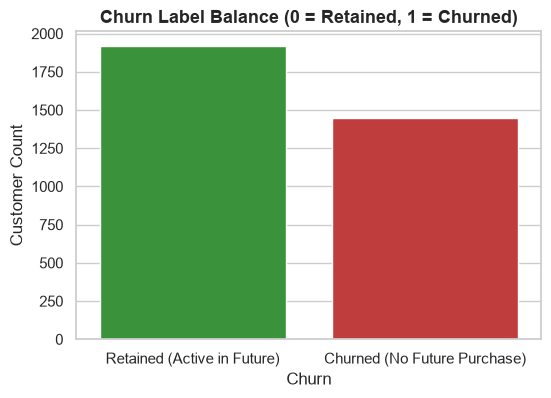

Churn
0    57.0
1    43.0
Name: proportion, dtype: float64


In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(data=churn_df, x='Churn', palette=['#2ca02c', '#d62728'])
plt.title('Churn Label Balance (0 = Retained, 1 = Churned)', fontsize=13, weight='bold')
plt.xticks([0, 1], ['Retained (Active in Future)', 'Churned (No Future Purchase)'])
plt.ylabel('Customer Count')
plt.show()

print(churn_df['Churn'].value_counts(normalize=True).round(3) * 100)


## 3. Training & Benchmarking Competitive Classifiers
Evaluating Logistic Regression, Random Forest, and XGBoost on an unseen 20% stratified test set.


In [4]:
from src.models.churn_prediction import CustomerChurnPredictor

predictor = CustomerChurnPredictor(data_path=Path('../data/processed/customer_churn_features.csv'), test_size=0.20)
predictor.load_and_split()
eval_df = predictor.train_and_evaluate()
eval_df


[Churn] Stratified Split: Train=2694 samples, Test=674 samples.
[Churn] Target Balance: {0: 0.57, 1: 0.43}


[Churn] Serialized Best Model (Random Forest Classifier) to: /Users/aryangupta/Desktop/e-commerce/models/best_churn_classifier.joblib


,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest Classifier,0.6528,0.5729,0.7586,0.6528,0.7163
1,XGBoost Classifier,0.6365,0.5613,0.7103,0.6271,0.7122
2,Logistic Regression,0.6439,0.5658,0.7414,0.6418,0.7105


## 4. ROC-AUC Performance Curves
Comparing True Positive Rate vs. False Positive Rate across all probability thresholds.


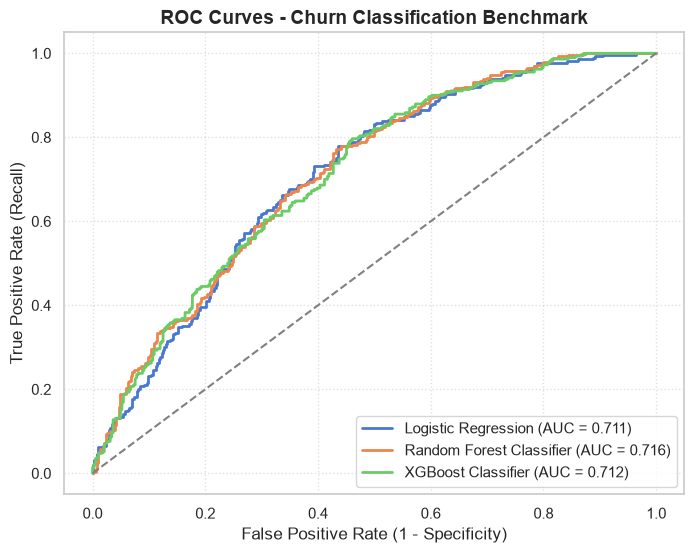

In [5]:
plt.figure(figsize=(8, 6))

for name, config in predictor.models.items():
    clf = config['model']
    X_test_eval = predictor.scaler.transform(predictor.X_test) if config['is_scaled'] else predictor.X_test
    y_probs = clf.predict_proba(X_test_eval)[:, 1]
    fpr, tpr, _ = roc_curve(predictor.y_test, y_probs)
    roc_score = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_score:.3f})", linewidth=2)

plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.title('ROC Curves - Churn Classification Benchmark', fontsize=14, weight='bold')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


## 5. Identifying Top Churn Risk Drivers
What behavioral indicators reveal an impending customer departure?


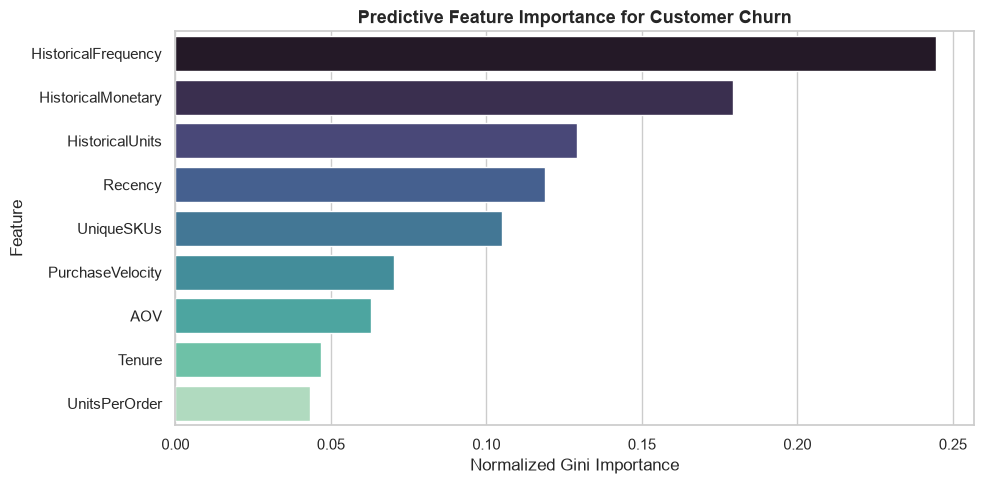

In [6]:
feat_imp = predictor.get_feature_importance()

plt.figure(figsize=(10, 5))
sns.barplot(data=feat_imp, x='Importance', y='Feature', palette='mako')
plt.title('Predictive Feature Importance for Customer Churn', fontsize=13, weight='bold')
plt.xlabel('Normalized Gini Importance')
plt.tight_layout()
plt.show()


## 6. Business Impact: Scoring the Cohort & VIP Revenue Exposure
Translating model probabilities into high-value revenue protection.


In [7]:
scored_df = predictor.score_all_customers()

tier_summary = scored_df.groupby('Churn_Risk_Tier').agg(
    CustomerCount=('CustomerID', 'count'),
    AvgChurnProbability=('Churn_Probability', 'mean'),
    TotalHistoricalSpend=('HistoricalMonetary', 'sum'),
    AvgHistoricalSpend=('HistoricalMonetary', 'mean')
).round(2).reset_index()

tier_summary['Revenue_Exposure (%)'] = round(
    (tier_summary['TotalHistoricalSpend'] / tier_summary['TotalHistoricalSpend'].sum()) * 100, 2
)
tier_summary


[Churn] Saved full cohort churn risk scoring to: /Users/aryangupta/Desktop/e-commerce/data/processed/customer_churn_predictions.csv


,Churn_Risk_Tier,CustomerCount,AvgChurnProbability,TotalHistoricalSpend,AvgHistoricalSpend,Revenue_Exposure (%)
0,High Risk,725,0.76,360898.97,497.79,6.71
1,Low Risk,991,0.16,4001387.55,4037.73,74.43
2,Medium Risk,1652,0.55,1013710.63,613.63,18.86


## 7. Actionable VIP Retention List
High-spending customers with >70% churn probability who require immediate executive intervention.


In [8]:
vip_at_risk = scored_df[
    (scored_df['Churn_Risk_Tier'] == 'High Risk') & (scored_df['HistoricalMonetary'] >= 1000)
].sort_values(by='HistoricalMonetary', ascending=False)

print(f"Total High-Value Accounts at Immediate Risk: {len(vip_at_risk)}")
print(f"Total Capital Exposure: £{vip_at_risk['HistoricalMonetary'].sum():,.2f}")

vip_at_risk[['CustomerID', 'HistoricalMonetary', 'HistoricalFrequency', 'Recency', 'Churn_Probability', 'Retention_Strategy']].head(10)


Total High-Value Accounts at Immediate Risk: 22
Total Capital Exposure: £191,892.72


,CustomerID,HistoricalMonetary,HistoricalFrequency,Recency,Churn_Probability,Retention_Strategy
0,12346,77183.60,1,235,0.8045,CRITICAL INTERVENTION: Assign dedicated accoun...
1964,15749,44534.30,3,144,0.7677,CRITICAL INTERVENTION: Assign dedicated accoun...
1595,15098,39916.50,3,91,0.7058,CRITICAL INTERVENTION: Assign dedicated accoun...
3254,18087,3202.92,1,200,0.7926,CRITICAL INTERVENTION: Assign dedicated accoun...
475,13135,3096.00,1,106,0.7290,CRITICAL INTERVENTION: Assign dedicated accoun...
2516,16754,2002.40,1,281,0.7417,CRITICAL INTERVENTION: Assign dedicated accoun...
2481,16698,1998.00,2,136,0.7346,CRITICAL INTERVENTION: Assign dedicated accoun...
1507,14935,1784.71,1,206,0.7485,CRITICAL INTERVENTION: Assign dedicated accoun...
264,12764,1693.88,1,226,0.7541,CRITICAL INTERVENTION: Assign dedicated accoun...
372,12967,1660.90,2,267,0.7207,CRITICAL INTERVENTION: Assign dedicated accoun...
